# Project MVP: ResNet-18 for Prior Myocardial Infarction Detection
This notebook implements a 1D ResNet-18 architecture for detecting prior Myocardial Infarction using Lead I ECG signals, replicating the methodology of the Obermeyer et al. 2026 paper using the PTB-XL dataset.

### Pipeline Stages:
1. Data loading and preprocessing (Lead I extraction).
2. Model architecture (1D ResNet-18).
3. Training & Evaluation Engine.
4. **Hyperparameter Optimization (Optuna)**.
5. Final training with best parameters.
6. Performance visualization.
7. Final Evaluation on Held-out Test Set.

In [1]:
import os
import pandas as pd
import numpy as np
import wfdb
import ast
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
from sklearn.metrics import roc_auc_score
import optuna

# Set device
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Using device: mps


## 1. Data Loading & Preprocessing

In [2]:
data_path = '../data/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3/'

def load_ptbxl_data(path):
    df = pd.read_csv(os.path.join(path, 'ptbxl_database.csv'), index_col=0)
    df.scp_codes = df.scp_codes.apply(lambda x: ast.literal_eval(x))
    return df

def aggregate_diagnostic(y_dic, agg_df):
    tmp = []
    for key in y_dic.keys():
        if key in agg_df.index: tmp.append(agg_df.loc[key].diagnostic_class)
    return list(set(tmp))

agg_df = pd.read_csv(os.path.join(data_path, 'scp_statements.csv'), index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]

df = load_ptbxl_data(data_path)
df['diagnostic_class'] = df.scp_codes.apply(aggregate_diagnostic, agg_df=agg_df)
df['MI'] = df.diagnostic_class.apply(lambda x: 1 if 'MI' in x else 0)

print(f"Total samples: {len(df)} | MI prevalence: {df.MI.mean()*100:.2f}%")

Total samples: 21799 | MI prevalence: 25.09%


In [3]:
class PTBXLDataset(Dataset):
    def __init__(self, df, base_path, lead_idx=0):
        self.df = df
        self.base_path = base_path
        self.lead_idx = lead_idx
        
    def __len__(self):
        return len(self.df)
    
    def __getitem__(self, idx):
        filename = os.path.join(self.base_path, self.df.iloc[idx].filename_lr)
        signal, meta = wfdb.rdsamp(filename)
        lead_signal = signal[:, self.lead_idx]
        lead_signal = (lead_signal - np.mean(lead_signal)) / (np.std(lead_signal) + 1e-8)
        label = self.df.iloc[idx].MI
        return torch.tensor(lead_signal, dtype=torch.float32).unsqueeze(0), torch.tensor(label, dtype=torch.float32)

train_df = df[df.strat_fold < 9]
val_df = df[df.strat_fold == 9]
test_df = df[df.strat_fold == 10]

print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Train: 17418, Val: 2183, Test: 2198


## 2. Model Architecture: 1D ResNet-18

In [4]:
def conv3x1(in_planes, out_planes, stride=1):
    return nn.Conv1d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)

class BasicBlock1D(nn.Module):
    expansion = 1
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock1D, self).__init__()
        self.conv1 = conv3x1(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm1d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x1(planes, planes)
        self.bn2 = nn.BatchNorm1d(planes)
        self.downsample = downsample

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        if self.downsample is not None: residual = self.downsample(x)
        out += residual
        out = self.relu(out)
        return out

class ResNet1D(nn.Module):
    def __init__(self, block, layers, num_classes=1):
        self.inplanes = 64
        super(ResNet1D, self).__init__()
        self.conv1 = nn.Conv1d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(64)
        self.relu = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv1d(self.inplanes, planes * block.expansion, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(planes * block.expansion),
            )
        layers = [block(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * block.expansion
        for _ in range(1, blocks): layers.append(block(self.inplanes, planes))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        x = self.avgpool(x)
        return self.fc(x.view(x.size(0), -1))

def resnet18_1d(): return ResNet1D(BasicBlock1D, [2, 2, 2, 2])

## 3. Training & Evaluation Engine

In [5]:
def evaluate(loader, model, criterion, device):
    model.eval()
    all_losses, all_preds, all_targets = [], [], []
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs).squeeze()
            if outputs.dim() == 0: outputs = outputs.unsqueeze(0)
            loss = criterion(outputs, targets)
            all_losses.append(loss.item())
            all_preds.extend(torch.sigmoid(outputs).cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
    return np.mean(all_losses), roc_auc_score(all_targets, all_preds)

def train_epoch(loader, model, criterion, optimizer, device, limit=None):
    model.train()
    losses, preds, targets = [], [], []
    for i, (inputs, labels) in enumerate(loader):
        if limit and i >= limit: break
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs).squeeze()
        if outputs.dim() == 0: outputs = outputs.unsqueeze(0)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        preds.extend(torch.sigmoid(outputs).detach().cpu().numpy())
        targets.extend(labels.cpu().numpy())
    return np.mean(losses), roc_auc_score(targets, preds)

## 4. Hyperparameter Optimization: Optuna

In [6]:
def objective(trial):
    # Hyperparameters to tune
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    
    # Dataloader with tuned batch size
    train_loader = DataLoader(PTBXLDataset(train_df, data_path), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(PTBXLDataset(val_df, data_path), batch_size=batch_size)
    
    model = resnet18_1d().to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()
    
    # Quick evaluation: 1 epoch on 5% of data
    train_epoch(train_loader, model, criterion, optimizer, device, limit=30)
    val_loss, val_auc = evaluate(val_loader, model, criterion, device)
    
    return val_auc

print("Starting Optuna Study...")
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=5)

print(f"Best trial AUC: {study.best_trial.value:.4f}")
print(f"Best params: {study.best_params}")

[I 2026-03-04 23:06:57,726] A new study created in memory with name: no-name-70d34a84-e734-4962-b457-d287f12ca73c


Starting Optuna Study...


[I 2026-03-04 23:07:08,736] Trial 0 finished with value: 0.7352404138770542 and parameters: {'lr': 0.0010651218263748239, 'batch_size': 64}. Best is trial 0 with value: 0.7352404138770542.


[I 2026-03-04 23:07:15,200] Trial 1 finished with value: 0.64899010392011 and parameters: {'lr': 1.230553458332077e-05, 'batch_size': 64}. Best is trial 0 with value: 0.7352404138770542.


[I 2026-03-04 23:07:21,217] Trial 2 finished with value: 0.7115191271612452 and parameters: {'lr': 0.004093527561149247, 'batch_size': 16}. Best is trial 0 with value: 0.7352404138770542.


[I 2026-03-04 23:07:28,092] Trial 3 finished with value: 0.6121739816505489 and parameters: {'lr': 0.002978537878294562, 'batch_size': 64}. Best is trial 0 with value: 0.7352404138770542.


[I 2026-03-04 23:07:32,847] Trial 4 finished with value: 0.6993034422127544 and parameters: {'lr': 1.9705285676886788e-05, 'batch_size': 16}. Best is trial 0 with value: 0.7352404138770542.


Best trial AUC: 0.7352
Best params: {'lr': 0.0010651218263748239, 'batch_size': 64}


## 5. Final Training with Best Parameters

In [7]:
best_params = study.best_params
train_loader = DataLoader(PTBXLDataset(train_df, data_path), batch_size=best_params['batch_size'], shuffle=True)
val_loader = DataLoader(PTBXLDataset(val_df, data_path), batch_size=best_params['batch_size'])

model = resnet18_1d().to(device)
optimizer = optim.Adam(model.parameters(), lr=best_params['lr'])
criterion = nn.BCEWithLogitsLoss()

history = {'train_loss': [], 'val_loss': [], 'train_auc': [], 'val_auc': []}
epochs = 3

for epoch in range(epochs):
    # Limit to 50 batches for MVP demo
    t_loss, t_auc = train_epoch(train_loader, model, criterion, optimizer, device, limit=50)
    v_loss, v_auc = evaluate(val_loader, model, criterion, device)
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_auc'].append(t_auc)
    history['val_auc'].append(v_auc)
    print(f"Epoch {epoch+1}: T-Loss {t_loss:.3f}, V-Loss {v_loss:.3f} | T-AUC {t_auc:.3f}, V-AUC {v_auc:.3f}")

Epoch 1: T-Loss 0.554, V-Loss 0.507 | T-AUC 0.682, V-AUC 0.743


Epoch 2: T-Loss 0.507, V-Loss 0.519 | T-AUC 0.721, V-AUC 0.726


Epoch 3: T-Loss 0.479, V-Loss 0.496 | T-AUC 0.758, V-AUC 0.736


## 6. Performance Visualization

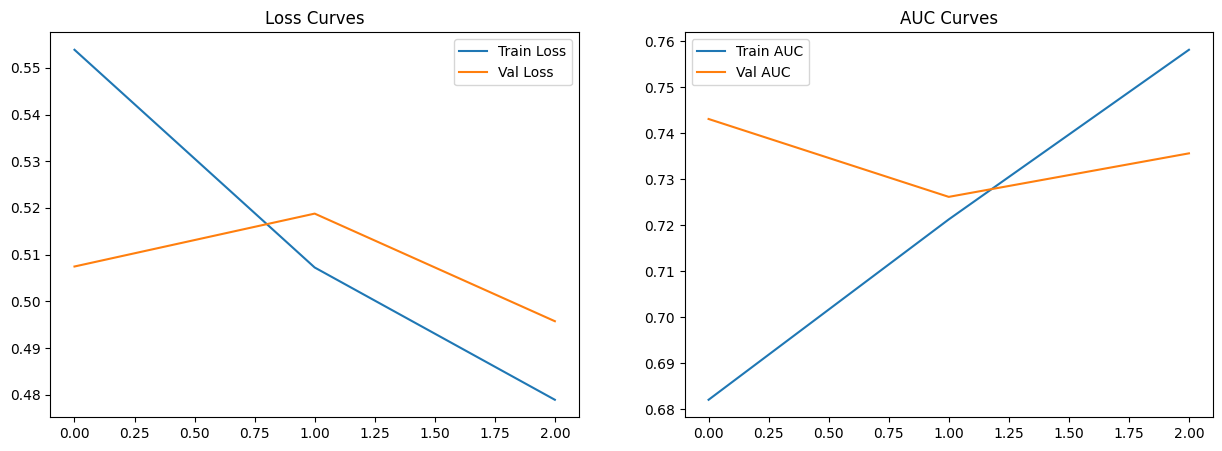

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(history['train_loss'], label='Train Loss'); ax1.plot(history['val_loss'], label='Val Loss')
ax1.set_title('Loss Curves'); ax1.legend()
ax2.plot(history['train_auc'], label='Train AUC'); ax2.plot(history['val_auc'], label='Val AUC')
ax2.set_title('AUC Curves'); ax2.legend()
plt.show()

## 7. Final Test Evaluation

In [9]:
test_loader = DataLoader(PTBXLDataset(test_df, data_path), batch_size=best_params['batch_size'])
t_loss, t_auc = evaluate(test_loader, model, criterion, device)
print(f"Final Test Performance: Loss {t_loss:.4f} | AUC {t_auc:.4f}")

Final Test Performance: Loss 0.5049 | AUC 0.7204
